# NetHealth: can Fitbit data detect or predict depression and anxiety scores?
**Run top to bottom.** Everything is cached in `HCI_PROJECT/nethealth_outputs/` on Drive, so re-runs are fast.

| Part | What it does |
|---|---|
| 0 (optional) | Copy the NetHealth files into Drive |
| 1 | Setup and Fitbit daily table |
| 2 | Survey labels: depression (CES-D), anxiety (BAI), BDI; date repair |
| 3 | 28-day Fitbit windows before each survey (leads 0, 14, 28 days) |
| 4 | Baselines (wave, previous score, Fitbit), student-level cross-validation, bootstrap over students |
| 5 | Controls: gender + race, and within-student change |
| 6 | Conformal prediction (90%) with coverage by gender and race |
| 7 | Small KAN vs logistic regression, learned curves |

Design rules: students never appear in both train and test; windows use only days BEFORE the survey; personal baselines use only earlier days; cutoffs follow the dataset's own group variables, never model results.

## Part 0 (optional): copy the NetHealth files into Drive
Skip this if `HCI_PROJECT/NetHealth` already holds the files.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, gdown
BASE0 = '/content/drive/MyDrive/HCI_PROJECT/NetHealth'
if not os.path.exists(os.path.join(BASE0, 'BasicSurvey(3-6-20).csv')):
    os.makedirs(BASE0, exist_ok=True)
    FILES = {'basic_survey_csv': '1pRHQOTXuCbZzTY1vm3imTwMVVIPZybJ_', 'basic_codebook': '1pRcrgtIsJhGd3nj_f_4h7wlFFA6yPQwZ',
             'fitbit_activity_csv': '1osKn9w7kvcankL_vVbqGOngVCS6BDt0B', 'activity_codebook': '1VxhBXH3GEKNcp1UrjlmMuU0FxM0ZnQaq',
             'fitbit_sleep_csv': '1ojCWQeBiE1BYo4i4HoBOsnIMQiJWpkI2', 'sleep_codebook': '1WLTco13eQ1nDH3t9B-9KM5yys1W3ZFkH',
             'calendar_csv': '1darYSQ4Tg8pn1IFcR9Mk3sXas53tSfjT', 'table4_questions': '1dGOg-iqnV3daHTCNXRp48gJkUHrslRUu',
             'table5_survey_dates': '1QcsIgZ0d4G3n8v5nhE_pCTDTDMcCQ1A7'}
    for name, fid in FILES.items():
        try: gdown.download(id=fid, output=BASE0 + '/', quiet=False)
        except Exception as e: print('FAILED', name, str(e)[:120])
print(sorted(os.listdir(BASE0)))

Mounted at /content/drive
['BasicSurvey(3-6-20).csv', 'Calendar.csv', 'Codebook Basic Survey(3-6-20).pdf', 'Codebook Fitbit Activity (1-30).pdf', 'Codebook Fitbit Sleep (1-30).pdf', 'FitbitActivity(1-30-20).csv', 'FitbitSleep(1-30-20).csv', 'Table 4 - Basic Survey Questions by Wave.pdf', 'Table5_ Basic and Network Survey Questionnaires (4-13-22).pdf']


## Part 1: setup and Fitbit daily table
Cleaning: activity days with under 50% wear are set to missing; sleep totals under 120 min are treated as not worn; the longest sleep period gives efficiency and bedtime.

In [2]:
import os, re, pickle, warnings, numpy as np, pandas as pd
warnings.filterwarnings('ignore')

BASE = '/content/drive/MyDrive/HCI_PROJECT/NetHealth'
OUT = '/content/drive/MyDrive/HCI_PROJECT/nethealth_outputs'; os.makedirs(OUT, exist_ok=True)
ACT_FILE = os.path.join(BASE, 'FitbitActivity(1-30-20).csv')
SLP_FILE = os.path.join(BASE, 'FitbitSleep(1-30-20).csv')
SURVEY_FILE = os.path.join(BASE, 'BasicSurvey(3-6-20).csv')

COMPLY_MIN = 50          # a day counts only if the Fitbit was worn >= 50% of the day (complypercent)
SLEEP_MIN_VALID = 120    # sleep totals under 120 min are treated as partial/not-worn -> missing
FEATS = ['steps', 'floors', 'sed_min', 'light_min', 'fair_min', 'very_min', 'hr_mean', 'hr_sd',
         'hr_fatburn', 'hr_cardio_peak', 'sleep_min', 'sleep_awake', 'sleep_eff', 'bedtime_h']
def save_pkl(o, n): pickle.dump(o, open(os.path.join(OUT, n), 'wb'))
def load_pkl(n):
    p = os.path.join(OUT, n); return pickle.load(open(p, 'rb')) if os.path.exists(p) else None

In [3]:
def read_lower(p):
    d = pd.read_csv(p, low_memory=False); d.columns = [c.strip().lower() for c in d.columns]; return d

daily = load_pkl('cache_daily.pkl')
if daily is None:
    act = read_lower(ACT_FILE); act['date'] = pd.to_datetime(act['datadate']).dt.normalize()
    A = pd.DataFrame({'egoid': act['egoid'], 'date': act['date'], 'comply': act['complypercent'],
        'steps': act['steps'], 'floors': act['floors'], 'sed_min': act['sedentaryminutes'],
        'light_min': act['lightlyactiveminutes'], 'fair_min': act['fairlyactiveminutes'], 'very_min': act['veryactiveminutes'],
        'hr_mean': act['meanrate'], 'hr_sd': act['sdrate'], 'hr_fatburn': act['fatburnmins'],
        'hr_cardio_peak': act['cardiomins'] + act['peakmins']})
    A = A.groupby(['egoid', 'date'], as_index=False).mean()
    bad = A['comply'] < COMPLY_MIN
    print(f'activity days with compliance < {COMPLY_MIN}%: {bad.mean():.1%} (set to missing)')
    act_cols = [c for c in A.columns if c not in ('egoid', 'date', 'comply')]
    A.loc[bad, act_cols] = np.nan

    slp = read_lower(SLP_FILE); slp['date'] = pd.to_datetime(slp['datadate']).dt.normalize()
    slp['bed_h'] = pd.to_timedelta(slp['timetobed'], errors='coerce').dt.total_seconds() / 3600
    slp.loc[slp['bed_h'] < 12, 'bed_h'] += 24                         # 01:00 -> 25.0 so bedtimes are continuous
    slp = slp.sort_values(['egoid', 'date', 'minsasleep'])
    longest = slp.groupby(['egoid', 'date']).tail(1)[['egoid', 'date', 'efficiency', 'bed_h']]
    S = slp.groupby(['egoid', 'date']).agg(sleep_min=('minsasleep', 'sum'), sleep_awake=('minsawake', 'sum')).reset_index()
    S = S.merge(longest.rename(columns={'efficiency': 'sleep_eff', 'bed_h': 'bedtime_h'}), on=['egoid', 'date'])
    short = S['sleep_min'] < SLEEP_MIN_VALID
    print(f'sleep days with < {SLEEP_MIN_VALID} min asleep: {short.mean():.1%} (set to missing)')
    S.loc[short, ['sleep_min', 'sleep_awake', 'sleep_eff', 'bedtime_h']] = np.nan

    D = A.merge(S, on=['egoid', 'date'], how='outer')
    daily = {}
    for uid, g in D.groupby('egoid'):
        g = g.set_index('date').sort_index()
        daily[int(uid)] = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq='D'))[FEATS + ['comply']]
    save_pkl(daily, 'cache_daily.pkl'); print('built and cached')
else: print('loaded from cache')
n_days = pd.Series({u: len(d) for u, d in daily.items()})
print(f'{len(daily)} students; days per student: median {n_days.median():.0f}, min {n_days.min()}, max {n_days.max()}')

cov = pd.concat([d[FEATS].notna() for d in daily.values()]).mean().round(3)
display(cov.to_frame('share of student-days with data'))

loaded from cache
623 students; days per student: median 768, min 1, max 1394


,share of student-days with data
steps,0.693
floors,0.693
sed_min,0.693
light_min,0.693
fair_min,0.693
very_min,0.693
hr_mean,0.693
hr_sd,0.693
hr_fatburn,0.693
hr_cardio_peak,0.693


## Part 2: labels
Depression = CES-D >= 16 (the dataset's "Depressed" group). Anxiety = BAI >= 22 (dataset's moderate/severe) with BAI >= 16 as a sensitivity task. BDI >= 14 (mild or worse) as a second depression scale. Missing wave-2 dates (Tier 3) get the wave's median date and are flagged.

In [4]:
# ===== LABELS: depression (CES-D), anxiety (BAI), BDI as a secondary depression scale =====
b = pd.read_csv(SURVEY_FILE, low_memory=False); b['egoid'] = b['egoid'].astype(int)

# task: (score column prefix, group column prefix, waves that contain the scale, cutoff for "high")
# Cutoffs follow the dataset's OWN group variables (checked in section 1 below), not model results.
SCALES = {
    'depression':   ('CESDOverall', 'CESDGroup', [1, 2, 4, 6, 8], 16),   # CES-D >= 16 = "Depressed" in CESDGroup
    'anxiety':      ('BAIsum',      'BAIgroup',  [1, 2, 3, 5, 7], 22),   # BAI >= 22 = "moderate" or "severe" in BAIgroup
    'anxiety_16':   ('BAIsum',      'BAIgroup',  [1, 2, 3, 5, 7], 16),   # SENSITIVITY: looser cutoff, more positives
    'bdi':          ('BDIsum',      'BDIgroup',  [2, 3, 5, 7],    14),   # BDI-II >= 14 = "mild" or worse in BDIgroup
}
def survey_date(w):                                   # end of survey if present, else start
    end = pd.to_datetime(b[f'EndDate_{w}'], errors='coerce'); st = pd.to_datetime(b[f'StartDate_{w}'], errors='coerce')
    return end.fillna(st).dt.normalize()

rows = []
for task, (pre, gpre, waves, cut) in SCALES.items():
    for w in waves:
        if f'{pre}_{w}' not in b: print('missing column', f'{pre}_{w}'); continue
        t = pd.DataFrame({'egoid': b['egoid'], 'task': task, 'wave': w, 'score': pd.to_numeric(b[f'{pre}_{w}'], errors='coerce'),
                          'date': survey_date(w), 'tier': b['Tier']})
        rows.append(t[t.score.notna()])
LAB = pd.concat(rows, ignore_index=True)
LAB['high'] = (LAB.score >= LAB.task.map({k: v[3] for k, v in SCALES.items()})).astype(int)


# ---- date repair (flagged as approximate; checked later as a sensitivity analysis) ----
IMPUTE_DATE_WAVES = [2]     # wave 2: dates are missing for Tier 3, but the wave only ran ~3 weeks -> use the wave's median date
OUTLIER_DAYS = 100          # a date >100 days from its wave's median is treated as a typo -> median date
LAB['date_approx'] = 0
for w in sorted(LAB.wave.unique()):
    dd = LAB.loc[LAB.wave == w, 'date'].dropna().sort_values()
    if len(dd) == 0: continue
    m = dd.iloc[len(dd) // 2]; msk = LAB.wave == w
    far = msk & LAB.date.notna() & ((LAB.date - m).abs() > pd.Timedelta(days=OUTLIER_DAYS))
    LAB.loc[far, ['date', 'date_approx']] = [m, 1]
    if w in IMPUTE_DATE_WAVES:
        miss = msk & LAB.date.isna(); LAB.loc[miss, ['date', 'date_approx']] = [m, 1]
print('labels with an approximate date:'); display(LAB[LAB.date_approx == 1].groupby(['task', 'wave']).size().to_frame('n_approx'))

print('=== 1. Do the dataset\'s own GROUP variables agree with my cutoffs? (score range per group) ===')
for task, (pre, gpre, waves, cut) in SCALES.items():
    w = waves[1] if len(waves) > 1 else waves[0]
    if f'{gpre}_{w}' in b:
        print(f'\n{task} ({pre}_{w}), my cutoff = {cut}'); display(b.groupby(b[f'{gpre}_{w}'])[f'{pre}_{w}'].agg(['count', 'min', 'max']))

print('\n=== 2. Labels per task and wave ===')
T = LAB.groupby(['task', 'wave']).agg(n_scores=('score', 'size'), n_with_date=('date', lambda s: s.notna().sum()),
        n_high=('high', 'sum'), mean_score=('score', 'mean'), first_date=('date', 'min'), last_date=('date', 'max')).round(2)
T['prevalence'] = (T.n_high / T.n_scores).round(3); display(T)

print('\n=== 3. Labels with NO survey date, by tier (these cannot get a Fitbit window yet) ===')
display(LAB[LAB.date.isna()].groupby(['task', 'wave', 'tier']).size().unstack(fill_value=0))
print('\n=== 4. Students, demographics ===')
STU = b.set_index('egoid')[['gender_1', 'race_1', 'Tier']].rename(columns={'gender_1': 'gender', 'race_1': 'race', 'Tier': 'tier'})
print('students with any label:', LAB.egoid.nunique(), '| with Fitbit data:', len(set(LAB.egoid) & set(daily)))
save_pkl((LAB, STU), 'cache_labels.pkl')

labels with an approximate date:


n_approx
task       wave          
anxiety    2          213
anxiety_16 2          213
bdi        2          222
depression 2          214
           4            7

=== 1. Do the dataset's own GROUP variables agree with my cutoffs? (score range per group) ===

depression (CESDOverall_2), my cutoff = 16


,count,min,max
CESDGroup_2,,,
Depressed,161,16.0,52.0
Not depressed,461,0.0,15.0



anxiety (BAIsum_2), my cutoff = 22


,count,min,max
BAIgroup_2,,,
57,1,57.0,57.0
low,576,0.0,21.0
moderate,34,22.0,35.0
severe,10,36.0,45.0


... (5 outputs left out)

n_scores  n_with_date  n_high  mean_score first_date  \
task       wave                                                         
anxiety    1          498          498      41        6.97 2015-08-03   
           2          621          621      45        7.00 2016-01-31   
           3          412          412      19        5.22 2016-06-20   
           5          365          365      40        9.10 2017-04-10   
           7          264          264      21        6.81 2018-04-26   
anxiety_16 1          498          498      68        6.97 2015-08-03   
           2          621          621      82        7.00 2016-01-31   
           3          412          412      36        5.22 2016-06-20   
           5          365          365      75        9.10 2017-04-10   
           7          264          264      33        6.81 2018-04-26   
bdi        2          661          661     123        8.27 2016-01-31   
           3          458          458      56        7.14 2016-06-20   
           5          386          386      67        6.74 2017-04-10   
           7          722          271      48        2.68 2018-04-26   
depression 1          498          498     141       13.23 2015-08-03   
           2          622          622     161       11.93 2016-01-31   
           4          377          377     122       13.31 2016-08-03   
           6          311          311      90       12.47 2017-11-09   
           8          184          184      45       11.45 2019-04-12   

                 last_date  prevalence  
task       wave                         
anxiety    1    2015-11-08       0.082  
           2    2016-02-22       0.072  
           3    2016-07-07       0.046  
           5    2017-05-01       0.110  
           7    2018-05-07       0.080  
anxiety_16 1    2015-11-08       0.137  
           2    2016-02-22       0.132  
           3    2016-07-07       0.087  
           5    2017-05-01       0.205  
           7    2018-05-07       0.125  
bdi        2    2016-02-23       0.186  
           3    2016-07-07       0.122  
           5    2017-05-01       0.174  
           7    2018-05-07       0.066  
depression 1    2015-11-08       0.283  
           2    2016-02-22       0.259  
           4    2016-12-13       0.324  
           6    2017-12-05       0.289  
           8    2019-05-06       0.245


=== 3. Labels with NO survey date, by tier (these cannot get a Fitbit window yet) ===


,tier,Tier 1,Tier 2,Tier 3
task,wave,,,
bdi,7,241,66,144



=== 4. Students, demographics ===
students with any label: 722 | with Fitbit data: 623


## Part 3: Fitbit windows before each survey
Lead 0 = the 28 days right before the survey (detection). Leads 14 and 28 end that many days earlier (forecast with a gap).

In [5]:
# ===== WINDOWS: Fitbit days before each survey (lead 0 = detection; lead > 0 = forecast with a gap) =====
import hashlib
W, LEADS, MIN_OBS_DAYS = 28, [0, 14, 28], 14        # window length, leads (days before survey the window ENDS), min days with data
LABD = LAB[LAB.date.notna() & LAB.egoid.isin(daily.keys())].copy().sort_values(['task', 'egoid', 'wave'])
LABD['prev_score'] = LABD.groupby(['task', 'egoid'])['score'].shift(1)
LABD['prev_gap_days'] = (LABD['date'] - LABD.groupby(['task', 'egoid'])['date'].shift(1)).dt.days
print(f'labels: {len(LAB)} total -> {len(LABD)} with a survey date and Fitbit data')

def summarize(X):                                   # X: (N, W, F) -> per-channel summaries over the window
    with np.errstate(all='ignore'):
        mean = np.nanmean(X, axis=1); last7 = np.nanmean(X[:, -7:], axis=1); first7 = np.nanmean(X[:, :7], axis=1)
        std = np.nanstd(X, axis=1); miss = np.isnan(X).mean(axis=1)
    return np.hstack([mean, last7, last7 - first7, std, miss])

def build(task, lead):
    X, P, rows = [], [], []
    for r in LABD[LABD.task == task].itertuples():
        d = daily[r.egoid]; end = r.date - pd.Timedelta(days=lead)
        idx = pd.date_range(end - pd.Timedelta(days=W), end - pd.Timedelta(days=1))
        win = d[FEATS].reindex(idx).values.astype(float)
        if (~np.isnan(win)).any(axis=1).sum() < MIN_OBS_DAYS: continue
        hist = d.loc[:idx[0] - pd.Timedelta(days=1), FEATS]               # the student's OWN earlier days only
        hm, hs, hc = hist.mean().values, hist.std().values, hist.count().values
        with np.errstate(all='ignore'): dev = (np.nanmean(win, axis=0) - hm) / hs
        dev[(hc < 14) | ~(hs > 0)] = np.nan
        X.append(win); P.append(dev); rows.append(r)
    R = pd.DataFrame(rows)
    return dict(X=np.array(X), S=summarize(np.array(X)), P=np.array(P), H=R[['prev_score', 'prev_gap_days']].values.astype(float),
                y=R['high'].values.astype(int), approx=R['date_approx'].values, score=R['score'].values, g=R['egoid'].values, wave=R['wave'].values, date=R['date'].values,
                gender=STU.reindex(R['egoid'])['gender'].values, race=STU.reindex(R['egoid'])['race'].values)

SIG = hashlib.md5(repr((W, LEADS, MIN_OBS_DAYS, {k: v[2:] for k, v in SCALES.items()}, IMPUTE_DATE_WAVES)).encode()).hexdigest()[:8]
DATA = load_pkl(f'cache_windows_{SIG}.pkl')
if DATA is None:
    DATA = {(t, L): build(t, L) for t in SCALES for L in LEADS}; save_pkl(DATA, f'cache_windows_{SIG}.pkl')
else: print('windows loaded from cache')

rows = []
for (t, L), D in DATA.items():
    rows.append(dict(task=t, lead=L, labels=len(D['y']), students=len(np.unique(D['g'])), positives=int(D['y'].sum()),
                     prevalence=round(D['y'].mean(), 3), approx_dates=int(D['approx'].sum()), with_prev_score=int((~np.isnan(D['H'][:, 0])).sum()),
                     **{f'w{w}': int((D['wave'] == w).sum()) for w in range(1, 9)}))
SUMMARY = pd.DataFrame(rows); display(SUMMARY); SUMMARY.to_csv(os.path.join(OUT, 'windows_summary.csv'), index=False)
print('RULE OF THUMB: want >= ~100 positives and >= ~150 students per task. Prevalence between 10% and 50% is comfortable.')

labels: 8539 total -> 7624 with a survey date and Fitbit data
windows loaded from cache


,task,lead,labels,students,positives,prevalence,approx_dates,with_prev_score,w1,w2,w3,w4,w5,w6,w7,w8
0,depression,0,959,462,268,0.279,14,940,10,334,0,278,0,241,0,96
1,depression,14,940,447,265,0.282,14,928,4,309,0,287,0,241,0,99
2,depression,28,951,449,267,0.281,12,943,2,307,0,294,0,247,0,101
3,anxiety,0,1035,448,69,0.067,8,1016,10,333,209,0,269,0,214,0
4,anxiety,14,1006,442,68,0.068,7,994,4,308,217,0,265,0,212,0
5,anxiety,28,1016,431,77,0.076,5,1008,2,306,222,0,272,0,214,0
6,anxiety_16,0,1035,448,128,0.124,8,1016,10,333,209,0,269,0,214,0
7,anxiety_16,14,1006,442,126,0.125,7,994,4,308,217,0,265,0,212,0
8,anxiety_16,28,1016,431,135,0.133,5,1008,2,306,222,0,272,0,214,0
9,bdi,0,1068,459,178,0.167,8,716,0,349,221,0,277,0,221,0


RULE OF THUMB: want >= ~100 positives and >= ~150 students per task. Prevalence between 10% and 50% is comfortable.


## Part 4: baselines
Key question: does the Fitbit add anything beyond the wave (season) and the student's previous score? Differences are paired bootstrap intervals over students.

In [6]:
# ===== BASELINES: does the Fitbit add anything beyond the wave (season) and the student's previous score? =====
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
SEEDS, K_FOLDS, NBOOT = [0, 1, 2, 3, 4], 5, 500

def make_lr(seed=0): return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                          LogisticRegression(C=0.05, class_weight='balanced', max_iter=3000))
def make_gb(seed=0): return make_pipeline(SimpleImputer(strategy='median'),
                          HistGradientBoostingClassifier(max_depth=3, max_iter=100, learning_rate=0.05, class_weight='balanced', random_state=seed))
def folds(g, seed, K):                                    # split by STUDENT: a student is never in train and test together
    u = np.unique(g); rng = np.random.RandomState(seed); rng.shuffle(u)
    for part in np.array_split(u, min(K, len(u))):
        te = np.isin(g, part); yield ~te, te
def oof(X, y, g, seed, make=make_lr):
    p = np.full(len(y), np.nan)
    for tr, te in folds(g, seed, K_FOLDS):
        if len(np.unique(y[tr])) < 2: p[te] = y[tr].mean(); continue
        m = make(seed); m.fit(X[tr], y[tr]); p[te] = m.predict_proba(X[te])[:, 1]
    return p
def within_wave_auc(y, p, wave):                          # mean AUROC inside each wave: removes the season effect
    a = [roc_auc_score(y[wave == w], p[wave == w]) for w in np.unique(wave)
         if (wave == w).sum() >= 30 and 0 < y[wave == w].sum() < (wave == w).sum()]
    return np.mean(a) if a else np.nan

def feature_sets(D):
    WV = np.stack([(D['wave'] == w) for w in range(1, 9)], axis=1).astype(float)
    PV = np.column_stack([D['H'], ~np.isnan(D['H'][:, 0])]).astype(float)       # previous score, days since, has-previous flag
    return {'wave only': WV, 'past score only': PV, 'wave + past': np.hstack([WV, PV]),
            'wearable S': D['S'], 'wearable P (vs own usual)': D['P'],
            'wave + wearable S': np.hstack([WV, D['S']]),
            'wave + past + wearable S+P': np.hstack([WV, PV, D['S'], D['P']])}

rows, OOF = [], {}
for (task, lead), D in DATA.items():
    y, g, wave = D['y'], D['g'], D['wave']; sets = feature_sets(D)
    models = [(n, X, make_lr) for n, X in sets.items()]
    models += [('GBM wave + past', sets['wave + past'], make_gb), ('GBM wave + past + wearable', sets['wave + past + wearable S+P'], make_gb)]
    for name, X, make in models:
        aucs, prs = [], []
        for s in SEEDS:
            p = oof(X, y, g, s, make); aucs.append(roc_auc_score(y, p)); prs.append(average_precision_score(y, p))
            if s == 0: OOF[(task, lead, name)] = p
        rows.append(dict(task=task, lead=lead, model=name, n=len(y), positives=int(y.sum()), prevalence=round(y.mean(), 3),
                         AUROC=np.mean(aucs), AUROC_sd=np.std(aucs), AUCPR=np.mean(prs), AUCPR_within_wave_AUROC=within_wave_auc(y, OOF[(task, lead, name)], wave)))
    print('done', task, lead)
BASE_RES = pd.DataFrame(rows).round(3).rename(columns={'AUCPR_within_wave_AUROC': 'AUROC_within_wave'})
BASE_RES.to_csv(os.path.join(OUT, 'baselines.csv'), index=False)
for (task, lead), G in BASE_RES.groupby(['task', 'lead'], sort=False):
    print(f'\n=== {task}  lead={lead}d  n={G.n.iloc[0]}  positives={G.positives.iloc[0]}  prevalence={G.prevalence.iloc[0]} ==='); display(G[['model', 'AUROC', 'AUROC_sd', 'AUCPR', 'AUROC_within_wave']].set_index('model'))

# --- does the Fitbit ADD anything? paired bootstrap over STUDENTS (95% CI of the AUROC difference) ---
def student_boot_diff(y, pa, pb, g, n=NBOOT, seed=0):
    ug = np.unique(g); idx = {u: np.where(g == u)[0] for u in ug}; rng = np.random.RandomState(seed); d = []
    for _ in range(n):
        ii = np.concatenate([idx[u] for u in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        d.append(roc_auc_score(y[ii], pa[ii]) - roc_auc_score(y[ii], pb[ii]))
    return np.percentile(d, [2.5, 97.5])
rows = []
for (task, lead), D in DATA.items():
    for a, bb in [('wave + wearable S', 'wave only'), ('wave + past + wearable S+P', 'wave + past'), ('GBM wave + past + wearable', 'GBM wave + past')]:
        pa, pb = OOF[(task, lead, a)], OOF[(task, lead, bb)]; lo, hi = student_boot_diff(D['y'], pa, pb, D['g'])
        rows.append(dict(task=task, lead=lead, with_wearable=a, without=bb, delta_AUROC=roc_auc_score(D['y'], pa) - roc_auc_score(D['y'], pb), ci_lo=lo, ci_hi=hi))
DELTA = pd.DataFrame(rows).round(3); DELTA.to_csv(os.path.join(OUT, 'baselines_wearable_added_value.csv'), index=False); display(DELTA)
print('A wearable gain is credible only if the CI is above 0 and it shows up for several leads / both depression tasks.')

done depression 0
done depression 14
done depression 28
done anxiety 0
done anxiety 14
done anxiety 28
done anxiety_16 0
done anxiety_16 14
done anxiety_16 28
done bdi 0
done bdi 14
done bdi 28

=== depression  lead=0d  n=959  positives=268  prevalence=0.279 ===


,AUROC,AUROC_sd,AUCPR,AUROC_within_wave
model,,,,
wave only,0.534,0.003,0.299,0.435
past score only,0.764,0.001,0.581,0.775
wave + past,0.770,0.003,0.585,0.762
wearable S,0.624,0.014,0.372,0.615
wearable P (vs own usual),0.541,0.004,0.310,0.542
wave + wearable S,0.622,0.012,0.373,0.603
wave + past + wearable S+P,0.766,0.008,0.573,0.770
GBM wave + past,0.739,0.006,0.549,0.741
GBM wave + past + wearable,0.733,0.007,0.539,0.727



=== depression  lead=14d  n=940  positives=265  prevalence=0.282 ===


,AUROC,AUROC_sd,AUCPR,AUROC_within_wave
model,,,,
wave only,0.530,0.006,0.302,0.450
past score only,0.766,0.001,0.581,0.783
wave + past,0.773,0.003,0.587,0.776
wearable S,0.605,0.006,0.357,0.593
wearable P (vs own usual),0.531,0.011,0.304,0.515
wave + wearable S,0.603,0.005,0.361,0.587
wave + past + wearable S+P,0.759,0.005,0.562,0.756
GBM wave + past,0.747,0.004,0.545,0.751
GBM wave + past + wearable,0.748,0.006,0.562,0.763



=== depression  lead=28d  n=951  positives=267  prevalence=0.281 ===


,AUROC,AUROC_sd,AUCPR,AUROC_within_wave
model,,,,
wave only,0.549,0.005,0.310,0.445
past score only,0.771,0.001,0.581,0.786
wave + past,0.780,0.002,0.590,0.779
wearable S,0.576,0.014,0.338,0.596
wearable P (vs own usual),0.524,0.013,0.293,0.501
wave + wearable S,0.579,0.013,0.339,0.583
wave + past + wearable S+P,0.747,0.006,0.540,0.762
GBM wave + past,0.748,0.005,0.543,0.730
GBM wave + past + wearable,0.759,0.005,0.552,0.770


... (16 outputs left out)


=== bdi  lead=28d  n=1058  positives=171  prevalence=0.162 ===


,AUROC,AUROC_sd,AUCPR,AUROC_within_wave
model,,,,
wave only,0.516,0.011,0.167,0.447
past score only,0.770,0.003,0.462,0.737
wave + past,0.773,0.003,0.466,0.733
wearable S,0.572,0.018,0.202,0.560
wearable P (vs own usual),0.497,0.004,0.165,0.503
wave + wearable S,0.569,0.015,0.199,0.555
wave + past + wearable S+P,0.738,0.008,0.423,0.728
GBM wave + past,0.750,0.004,0.440,0.710
GBM wave + past + wearable,0.714,0.007,0.385,0.705


,task,lead,with_wearable,without,delta_AUROC,ci_lo,ci_hi
0,depression,0,wave + wearable S,wave only,0.074,0.027,0.115
1,depression,0,wave + past + wearable S+P,wave + past,-0.004,-0.030,0.021
2,depression,0,GBM wave + past + wearable,GBM wave + past,-0.023,-0.051,0.002
3,depression,14,wave + wearable S,wave only,0.060,0.011,0.112
4,depression,14,wave + past + wearable S+P,wave + past,-0.019,-0.044,0.004
5,depression,14,GBM wave + past + wearable,GBM wave + past,0.002,-0.024,0.025
6,depression,28,wave + wearable S,wave only,0.036,-0.019,0.081
7,depression,28,wave + past + wearable S+P,wave + past,-0.028,-0.051,-0.006
8,depression,28,GBM wave + past + wearable,GBM wave + past,0.021,-0.002,0.045
9,anxiety,0,wave + wearable S,wave only,-0.021,-0.129,0.069


A wearable gain is credible only if the CI is above 0 and it shows up for several leads / both depression tasks.


## Part 5: controls
(a) Gender and race are added: activity and depression both differ by gender. (b) Within-student change between two surveys, after removing wave-pair shifts.

In [7]:
# ===== CELL 7: (a) control for gender + race, (b) within-student CHANGE analysis =====
def demo_matrix(D):
    return pd.get_dummies(pd.DataFrame({'gender': D['gender'], 'race': D['race']}).astype(str)).astype(float).values

print('=== (a) Does the Fitbit still add anything after controlling for wave + gender + race? ===')
rows = []
for (task, lead), D in DATA.items():
    y, g = D['y'], D['g']; WV = feature_sets(D)['wave only']; PV = feature_sets(D)['past score only']; DM = demo_matrix(D)
    sets = {'wave+demo': np.hstack([WV, DM]), 'wave+demo+wearable S': np.hstack([WV, DM, D['S']]),
            'wave+demo+past': np.hstack([WV, DM, PV]), 'wave+demo+past+wearable S+P': np.hstack([WV, DM, PV, D['S'], D['P']])}
    P0, res = {}, {}
    for name, X in sets.items():
        res[name] = np.mean([roc_auc_score(y, oof(X, y, g, s)) for s in SEEDS]); P0[name] = oof(X, y, g, 0)
    lo1, hi1 = student_boot_diff(y, P0['wave+demo+wearable S'], P0['wave+demo'], g)
    lo2, hi2 = student_boot_diff(y, P0['wave+demo+past+wearable S+P'], P0['wave+demo+past'], g)
    rows.append(dict(task=task, lead=lead, **{k: round(v, 3) for k, v in res.items()},
                     delta_wearable_over_demo=round(res['wave+demo+wearable S'] - res['wave+demo'], 3), ci1=f'[{lo1:.3f}, {hi1:.3f}]',
                     delta_wearable_over_past=round(res['wave+demo+past+wearable S+P'] - res['wave+demo+past'], 3), ci2=f'[{lo2:.3f}, {hi2:.3f}]'))
DEMO = pd.DataFrame(rows); DEMO.to_csv(os.path.join(OUT, 'demographic_control.csv'), index=False); display(DEMO)

print('\n=== (b) Within-student CHANGE: when a student\'s Fitbit window changes between two surveys, does their score change the same way? ===')
from scipy.stats import spearmanr
def change_table(task, n_boot=NBOOT):
    D = DATA[(task, 0)]; nF = len(FEATS)
    df = pd.DataFrame(D['S'][:, :nF], columns=FEATS); df['egoid'] = D['g']; df['wave'] = D['wave']; df['score'] = D['score']
    df = df.sort_values(['egoid', 'wave']).reset_index(drop=True); prev = df.groupby('egoid').shift(1)
    ch = df[FEATS + ['score']] - prev[FEATS + ['score']]; ch['egoid'] = df['egoid']
    ch['pair'] = df['wave'].astype(str) + '<-' + prev['wave'].astype('Int64').astype(str); ch = ch[prev['wave'].notna()].copy()
    for c in FEATS + ['score']: ch[c] = ch[c] - ch.groupby('pair')[c].transform('mean')       # remove season/wave-pair shifts
    out = []; rng = np.random.RandomState(0); ug = ch['egoid'].unique(); groups = {u: ch[ch.egoid == u] for u in ug}
    for f in FEATS:
        s = ch[[f, 'score', 'egoid']].dropna()
        if len(s) < 60: continue
        rho = spearmanr(s[f], s['score'])[0]; gs = {u: s[s.egoid == u] for u in s.egoid.unique()}; us = list(gs); bs = []
        for _ in range(n_boot):
            b_ = pd.concat([gs[u] for u in rng.choice(us, len(us))])
            if b_[f].nunique() > 1: bs.append(spearmanr(b_[f], b_['score'])[0])
        out.append(dict(task=task, channel=f, n_pairs=len(s), n_students=s.egoid.nunique(), rho=rho, ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
    return pd.DataFrame(out)
CHG = pd.concat([change_table(t) for t in SCALES], ignore_index=True).round(3); CHG.to_csv(os.path.join(OUT, 'within_student_change.csv'), index=False)
CHG['ci_excludes_0'] = (CHG.ci_lo > 0) | (CHG.ci_hi < 0)
display(CHG[CHG.ci_excludes_0].drop(columns='ci_excludes_0'))
print(f'{CHG.ci_excludes_0.sum()} of {len(CHG)} change-correlations have a 95% CI excluding 0 (about {0.05 * len(CHG):.0f} expected by chance; anxiety and anxiety_16 share labels).')

=== (a) Does the Fitbit still add anything after controlling for wave + gender + race? ===


,task,lead,wave+demo,wave+demo+wearable S,wave+demo+past,wave+demo+past+wearable S+P,delta_wearable_over_demo,ci1,delta_wearable_over_past,ci2
0,depression,0,0.585,0.632,0.765,0.762,0.047,"[-0.007, 0.079]",-0.003,"[-0.028, 0.020]"
1,depression,14,0.592,0.619,0.773,0.760,0.027,"[-0.029, 0.059]",-0.013,"[-0.043, 0.004]"
2,depression,28,0.601,0.593,0.780,0.747,-0.009,"[-0.049, 0.029]",-0.033,"[-0.048, -0.007]"
3,anxiety,0,0.676,0.612,0.857,0.788,-0.064,"[-0.148, -0.010]",-0.069,"[-0.136, -0.046]"
4,anxiety,14,0.663,0.653,0.855,0.818,-0.010,"[-0.081, 0.052]",-0.037,"[-0.093, -0.022]"
5,anxiety,28,0.664,0.658,0.866,0.820,-0.006,"[-0.048, 0.063]",-0.046,"[-0.070, -0.013]"
6,anxiety_16,0,0.654,0.633,0.843,0.804,-0.021,"[-0.081, 0.017]",-0.039,"[-0.077, -0.013]"
7,anxiety_16,14,0.646,0.624,0.841,0.780,-0.022,"[-0.072, 0.028]",-0.062,"[-0.109, -0.042]"
8,anxiety_16,28,0.658,0.644,0.858,0.806,-0.014,"[-0.059, 0.029]",-0.052,"[-0.085, -0.040]"
9,bdi,0,0.561,0.594,0.766,0.747,0.032,"[-0.019, 0.080]",-0.019,"[-0.051, 0.011]"



=== (b) Within-student CHANGE: when a student's Fitbit window changes between two surveys, does their score change the same way? ===


,task,channel,n_pairs,n_students,rho,ci_lo,ci_hi
44,bdi,sed_min,603,315,0.096,0.024,0.182


1 of 56 change-correlations have a 95% CI excluding 0 (about 3 expected by chance; anxiety and anxiety_16 share labels).


## Part 6: conformal prediction
Class-conditional split conformal on the best model (wave + previous score), split by student 60/20/20, 30 repeats, target coverage 90%. Group coverage for small groups is exploratory.

In [8]:
# ===== CELL 8: conformal prediction (90% target) on the best model (wave + previous score), coverage by gender and race =====
ALPHA, N_REP, CONF_LEAD = 0.10, 30, 0
CONF_TASKS = ['depression', 'anxiety_16', 'bdi']          # 'anxiety' (>=22) has too few positives for a calibration split

def conformal_groups(task, lead=CONF_LEAD, alpha=ALPHA, n_rep=N_REP):
    D = DATA[(task, lead)]; fs = feature_sets(D); X = np.hstack([fs['wave only'], fs['past score only']])   # no demographics as INPUT
    y, g = D['y'], D['g']; gender, race = D['gender'].astype(str), D['race'].astype(str); ug = np.unique(g)
    per_rep, pooled = [], []
    for r in range(n_rep):
        u = np.random.RandomState(r).permutation(ug); n = len(u)
        te_u, ca_u, tr_u = u[:int(.2 * n)], u[int(.2 * n):int(.4 * n)], u[int(.4 * n):]      # split by STUDENT: 60 / 20 / 20
        tr, ca, te = np.isin(g, tr_u), np.isin(g, ca_u), np.isin(g, te_u)
        if len(np.unique(y[tr])) < 2 or y[ca].sum() < 8 or (1 - y[ca]).sum() < 8: continue
        m = make_lr(); m.fit(X[tr], y[tr]); pc = m.predict_proba(X[ca])[:, 1]; pt = m.predict_proba(X[te])[:, 1]
        q = {}
        for k, sc in [(1, 1 - pc[y[ca] == 1]), (0, pc[y[ca] == 0])]:                  # surprise = 1 - P(true label); cutoff per class
            lvl = min(1.0, np.ceil((len(sc) + 1) * (1 - alpha)) / len(sc)); q[k] = np.quantile(sc, lvl, method='higher')
        in1, in0 = (1 - pt) <= q[1], pt <= q[0]; yt = y[te]; cov = np.where(yt == 1, in1, in0)
        per_rep.append(dict(coverage=cov.mean(), coverage_pos=cov[yt == 1].mean(), coverage_neg=cov[yt == 0].mean(),
                            avg_set_size=(in1.astype(int) + in0).mean(), share_not_sure=(in1 & in0).mean(), share_single=(in1 ^ in0).mean()))
        pooled.append(pd.DataFrame(dict(student=g[te], y=yt, cov=cov, size=in1.astype(int) + in0, gender=gender[te], race=race[te])))
    return pd.DataFrame(per_rep), pd.concat(pooled)

summ, grp = [], []
for task in CONF_TASKS:
    R, P = conformal_groups(task)
    summ.append(dict(task=task, reps=len(R), target=1 - ALPHA, **{c: f'{R[c].mean():.3f}±{R[c].std():.3f}' for c in R.columns}))
    for gtype in ['gender', 'race']:
        for name, G in P.groupby(gtype):
            if name == 'nan' or G.student.nunique() < 15: continue
            grp.append(dict(task=task, group_type=gtype, group=name, students=G.student.nunique(), coverage=round(G['cov'].mean(), 3),
                            coverage_on_high=round(G.loc[G.y == 1, 'cov'].mean(), 3), avg_set_size=round(G['size'].mean(), 2)))
SUMM = pd.DataFrame(summ); GRP = pd.DataFrame(grp)
SUMM.to_csv(os.path.join(OUT, 'conformal_overall.csv'), index=False); GRP.to_csv(os.path.join(OUT, 'conformal_by_group.csv'), index=False)
display(SUMM.T); display(GRP)
print('Target coverage is 0.90. coverage_on_high = coverage on days/students whose true label is HIGH (the important one).')
print('Groups with < 15 students in the test splits are hidden. Small groups (e.g. African-American) are exploratory.')

,0,1,2
task,depression,anxiety_16,bdi
reps,30,30,30
target,0.9,0.9,0.9
coverage,0.907±0.033,0.912±0.025,0.931±0.026
coverage_pos,0.915±0.072,0.965±0.054,0.937±0.066
coverage_neg,0.904±0.041,0.904±0.027,0.929±0.027
avg_set_size,1.617±0.119,1.569±0.141,1.635±0.142
share_not_sure,0.617±0.119,0.569±0.141,0.635±0.142
share_single,0.383±0.119,0.431±0.141,0.365±0.142


,task,group_type,group,students,coverage,coverage_on_high,avg_set_size
0,depression,gender,Female,234,0.887,0.920,1.61
1,depression,gender,Male,227,0.928,0.914,1.62
2,depression,race,African-American,27,0.940,0.974,1.44
3,depression,race,Asian-American,41,0.870,0.877,1.62
4,depression,race,Foreign Student,28,0.790,0.867,1.62
5,depression,race,Latino/a,62,0.933,0.929,1.68
6,depression,race,White,301,0.916,0.919,1.62
7,anxiety_16,gender,Female,226,0.901,0.982,1.56
8,anxiety_16,gender,Male,222,0.922,0.917,1.58
9,anxiety_16,race,African-American,28,0.811,0.985,1.50


Target coverage is 0.90. coverage_on_high = coverage on days/students whose true label is HIGH (the important one).
Groups with < 15 students in the test splits are hidden. Small groups (e.g. African-American) are exploratory.


## Part 7: small KAN
Same regularised setup as in SSAQS (2 or 4 hidden units, strong regularisation). All configurations reported. Curves are fitted on all students for shape only and describe differences BETWEEN students.

done depression
done bdi
done anxiety_16


,task,model,AUROC,AUROC_sd
0,depression,LR (14 window means),0.629,0.009
1,depression,KAN H=2 lam=0.1 ep=30,0.623,0.009
2,depression,KAN H=4 lam=0.1 ep=30,0.623,0.006
3,bdi,LR (14 window means),0.611,0.010
4,bdi,KAN H=2 lam=0.1 ep=30,0.579,0.008
5,bdi,KAN H=4 lam=0.1 ep=30,0.581,0.017
6,anxiety_16,LR (14 window means),0.593,0.008
7,anxiety_16,KAN H=2 lam=0.1 ep=30,0.571,0.012
8,anxiety_16,KAN H=4 lam=0.1 ep=30,0.567,0.008


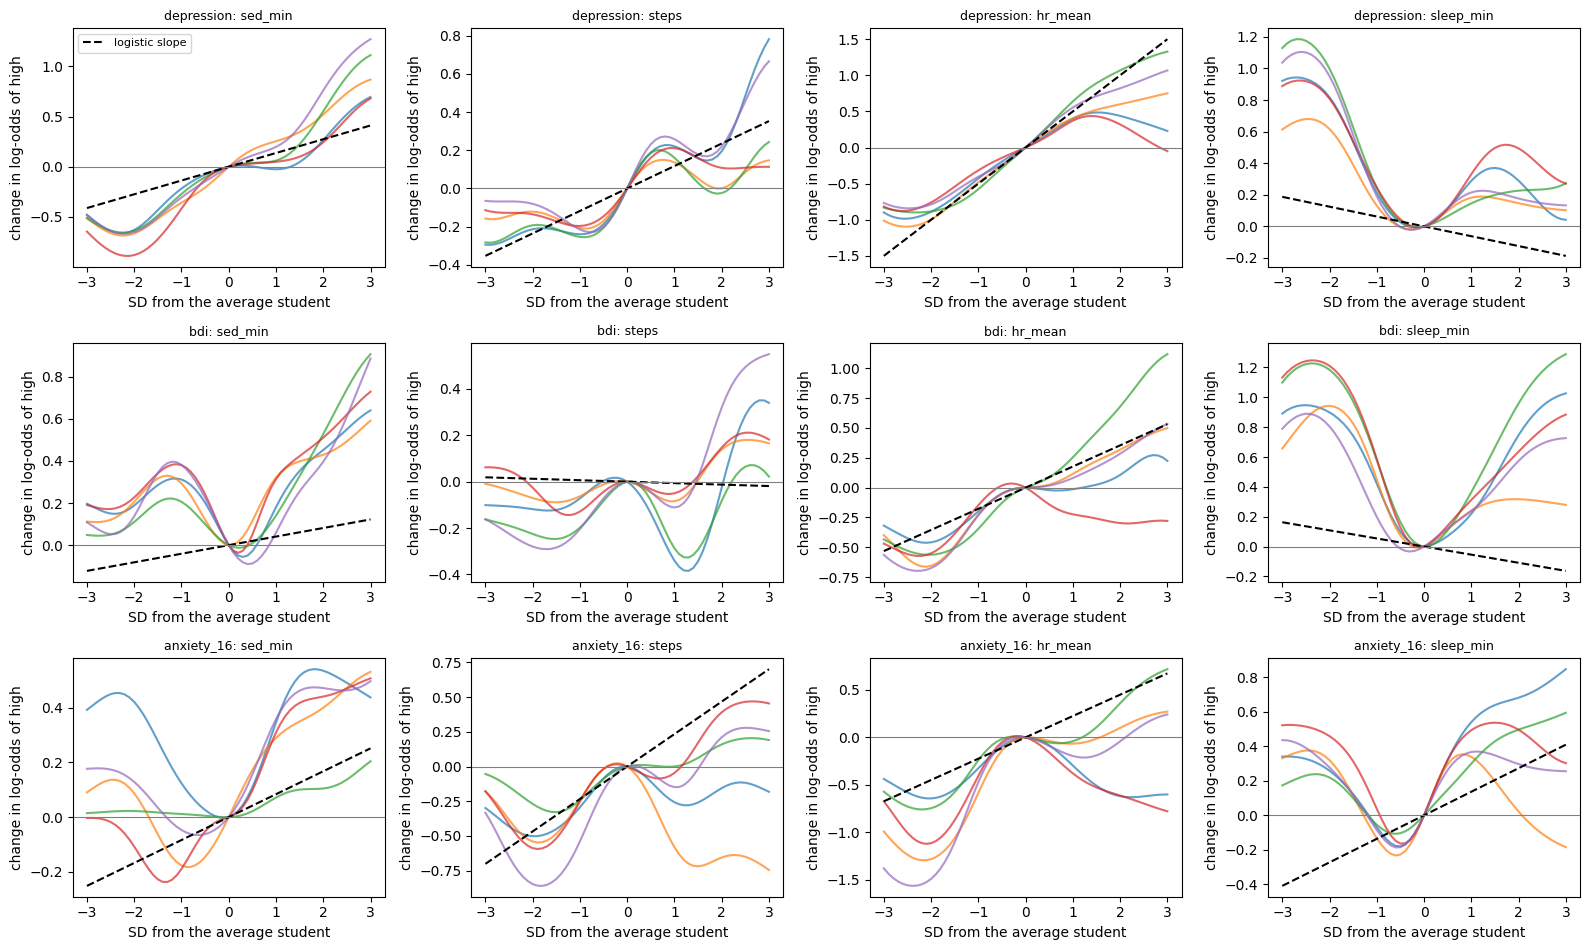

,task,feature,mean_seed_corr,logistic_slope
0,depression,sed_min,0.977,0.137
1,depression,steps,0.908,0.118
2,depression,hr_mean,0.954,0.501
3,depression,sleep_min,0.965,-0.062
4,bdi,sed_min,0.930,0.041
5,bdi,steps,0.777,-0.006
6,bdi,hr_mean,0.778,0.177
7,bdi,sleep_min,0.893,-0.054
8,anxiety_16,sed_min,0.839,0.084
9,anxiety_16,steps,0.464,0.234


In [9]:
# ===== CELL 9: small KAN on the Fitbit window MEANS (same regularised setup as SSAQS), compared with logistic regression =====
import torch, torch.nn as nn
import matplotlib.pyplot as plt
torch.set_num_threads(2)
KAN_TASKS, KAN_LEAD = ['depression', 'bdi', 'anxiety_16'], 0
CONFIGS = [dict(H=2, lam=1e-1, ep=30), dict(H=4, lam=1e-1, ep=30)]           # all reported, none cherry-picked
nF = len(FEATS)                                                              # first 14 columns of D['S'] = window means

class KANLayer(nn.Module):
    def __init__(self, n_in, n_out, G=8, lo=-3., hi=3.):
        super().__init__()
        self.register_buffer('c', torch.linspace(lo, hi, G)); self.h = (hi - lo) / (G - 1)
        self.coef = nn.Parameter(torch.randn(n_out, n_in, G) * 0.1)
        self.w = nn.Parameter(torch.randn(n_out, n_in) / np.sqrt(n_in)); self.b = nn.Parameter(torch.zeros(n_out))
    def forward(self, x):
        basis = torch.exp(-((x.unsqueeze(-1) - self.c) / self.h) ** 2)
        return torch.einsum('bik,oik->bo', basis, self.coef) + nn.functional.silu(x) @ self.w.T + self.b
    def reg(self): return self.coef.abs().mean() + (self.coef[..., 1:] - self.coef[..., :-1]).pow(2).mean()
class KANNet(nn.Module):
    def __init__(self, n_in, H=2, G=8):
        super().__init__(); self.l1 = KANLayer(n_in, H, G); self.l2 = KANLayer(H, 1, G)
    def forward(self, x): return self.l2(torch.tanh(self.l1(x))).squeeze(-1)

def train_kan(X, y, seed, H, epochs, lam):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
    net = KANNet(X.shape[1], H); opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y).sum() / max(y.sum(), 1), dtype=torch.float32))
    for ep in range(epochs):
        perm = rng.permutation(len(y))
        for b in range(0, len(y), 128):
            bi = perm[b:b + 128]; opt.zero_grad()
            (lossf(net(Xt[bi]), yt[bi]) + lam * (net.l1.reg() + net.l2.reg())).backward(); opt.step()
    return net.eval()
def predict_kan(net, X):
    with torch.no_grad(): return torch.sigmoid(net(torch.tensor(X, dtype=torch.float32))).numpy()
def standardise(Xtr, Xall):                                                   # statistics from TRAIN students only
    mu, sd = np.nanmean(Xtr, 0), np.nanstd(Xtr, 0) + 1e-6
    return np.nan_to_num(np.clip((Xall - mu) / sd, -4, 4), nan=0.0)
def kan_oof(Xraw, y, g, seed, cfg):
    p = np.full(len(y), np.nan)
    for tr, te in folds(g, seed, K_FOLDS):
        if len(np.unique(y[tr])) < 2: p[te] = y[tr].mean(); continue
        Z = standardise(Xraw[tr], Xraw); p[te] = predict_kan(train_kan(Z[tr], y[tr], seed, cfg['H'], cfg['ep'], cfg['lam']), Z[te])
    return p

rows = []
for task in KAN_TASKS:
    D = DATA[(task, KAN_LEAD)]; y, g = D['y'], D['g']; Xraw = D['S'][:, :nF]
    lr = [roc_auc_score(y, oof(Xraw, y, g, s)) for s in SEEDS]
    rows.append(dict(task=task, model='LR (14 window means)', AUROC=np.mean(lr), AUROC_sd=np.std(lr)))
    for cfg in CONFIGS:
        a = [roc_auc_score(y, kan_oof(Xraw, y, g, s, cfg)) for s in SEEDS]
        rows.append(dict(task=task, model=f"KAN H={cfg['H']} lam={cfg['lam']} ep={cfg['ep']}", AUROC=np.mean(a), AUROC_sd=np.std(a)))
    print('done', task)
KANRES = pd.DataFrame(rows).round(3); KANRES.to_csv(os.path.join(OUT, 'kan_vs_lr_nethealth.csv'), index=False); display(KANRES)

# curves from the H=2 KAN fitted on ALL students (shape only, not a score); x-axis = SD from the average student
PLOT = ['sed_min', 'steps', 'hr_mean', 'sleep_min']; grid = np.linspace(-3, 3, 61)
fig, axes = plt.subplots(len(KAN_TASKS), len(PLOT), figsize=(4 * len(PLOT), 3.2 * len(KAN_TASKS)), squeeze=False); stab = []
for r_, task in enumerate(KAN_TASKS):
    D = DATA[(task, KAN_LEAD)]; y = D['y']; Xraw = D['S'][:, :nF]; Z = standardise(Xraw, Xraw)
    nets = [train_kan(Z, y, s, 2, 30, 1e-1) for s in SEEDS]
    lrm = LogisticRegression(C=0.05, class_weight='balanced', max_iter=3000).fit(Z, y)
    for c_, fname in enumerate(PLOT):
        j = FEATS.index(fname); curves = []
        for net in nets:
            Zg = np.zeros((len(grid), nF), dtype=np.float32); Zg[:, j] = grid
            with torch.no_grad(): lg = net(torch.tensor(Zg)).numpy()
            curves.append(lg - lg[len(grid) // 2]); axes[r_, c_].plot(grid, curves[-1], alpha=0.7)
        axes[r_, c_].plot(grid, lrm.coef_[0][j] * grid, 'k--', lw=1.5, label='logistic slope')
        C = np.corrcoef(np.array(curves)); stab.append(dict(task=task, feature=fname, mean_seed_corr=C[np.triu_indices(len(SEEDS), 1)].mean(), logistic_slope=lrm.coef_[0][j]))
        axes[r_, c_].axhline(0, color='gray', lw=0.8); axes[r_, c_].set_title(f'{task}: {fname}', fontsize=9); axes[r_, c_].set_xlabel('SD from the average student'); axes[r_, c_].set_ylabel('change in log-odds of high')
        if r_ == 0 and c_ == 0: axes[r_, c_].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'kan_curves_nethealth.png'), dpi=150); plt.show()
STAB = pd.DataFrame(stab).round(3); STAB.to_csv(os.path.join(OUT, 'kan_curve_stability_nethealth.csv'), index=False); display(STAB)

In [10]:
# ===== Files saved in nethealth_outputs/ =====
for f in sorted(os.listdir(OUT)):
    if not f.startswith('cache_'): print(f)

baselines.csv
baselines_wearable_added_value.csv
conformal_by_group.csv
conformal_overall.csv
demographic_control.csv
kan_curve_stability_nethealth.csv
kan_curves_nethealth.png
kan_vs_lr_nethealth.csv
windows_summary.csv
within_student_change.csv
